In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn import linear_model as lm
from sklearn.linear_model import RidgeClassifier

In [2]:
aqs_raw = pd.read_csv("../Data/LA_AQS_2023.csv")
aqs_raw["Date (Local)"] = pd.to_datetime(aqs_raw["Date (Local)"])

print(aqs_raw.shape)
aqs_raw.head()

(22160, 34)


,State Code,County Code,Site Number,Parameter Code,POC,Latitude,Longitude,Datum,Parameter Name,Duration Description,...,AQI,Daily Criteria Indicator,Tribe Name,State Name,County Name,City Name,Local Site Name,Address,MSA or CBSA Name,Data Source
0,6,37,1103,68103,1,34.06659,-118.22688,WGS84,Ambient Min Temperature,24 HOUR,...,.,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
1,6,37,1103,42602,3,34.06659,-118.22688,WGS84,Nitrogen dioxide (NO2),1 HOUR,...,16,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
2,6,37,1103,62201,1,34.06659,-118.22688,WGS84,Relative Humidity,1 HOUR,...,.,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
3,6,37,1103,62101,1,34.06659,-118.22688,WGS84,Outdoor Temperature,1 HOUR,...,.,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
4,6,37,1103,42603,1,34.06659,-118.22688,WGS84,Oxides of nitrogen (NOx),1 HOUR,...,.,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart


In [3]:
o3 = aqs_raw[
    (aqs_raw["Parameter Name"] == "Ozone")
    & (aqs_raw["Duration Description"] == "1 HOUR")
][["Date (Local)", "Arithmetic Mean"]].copy()

o3 = o3.rename(columns={"Arithmetic Mean": "O3_ppm"})
o3["O3_ppb"] = o3["O3_ppm"] * 1000
o3.head()

,Date (Local),O3_ppm,O3_ppb
20,2023-01-01,0.031708,31.708
64,2023-01-02,0.015792,15.792
204,2023-01-03,0.025000,25.000
228,2023-01-04,0.020500,20.500
271,2023-01-05,0.027375,27.375


In [4]:
no2 = aqs_raw[
    (aqs_raw["Parameter Name"] == "Nitrogen dioxide (NO2)")
    & (aqs_raw["Pollutant Standard"] == "NO2 1-hour 2010")
][["Date (Local)", "Arithmetic Mean"]].copy()

no2 = (
    no2.groupby("Date (Local)", as_index=False)["Arithmetic Mean"]
    .mean()
    .rename(columns={"Arithmetic Mean": "NO2_ppb"})
)
no2.head()

,Date (Local),NO2_ppb
0,2023-01-01,4.683333
1,2023-01-02,15.068750
2,2023-01-03,11.662500
3,2023-01-04,14.363637
4,2023-01-05,11.027083


In [5]:
pm25 = aqs_raw[
    (aqs_raw["Parameter Name"] == "PM2.5 - Local Conditions")
    & (aqs_raw["Duration Description"] == "1 HOUR")
][["Date (Local)", "Arithmetic Mean"]].copy()

pm25 = (
    pm25.groupby("Date (Local)", as_index=False)["Arithmetic Mean"]
    .mean()
    .rename(columns={"Arithmetic Mean": "PM25_ugm3"})
)
pm25.head()

,Date (Local),PM25_ugm3
0,2023-01-01,5.087500
1,2023-01-02,9.187500
2,2023-01-03,4.312500
3,2023-01-04,4.266667
4,2023-01-05,6.704167


In [6]:
aqs = pd.merge(
    o3[["Date (Local)", "O3_ppb"]],
    no2,
    on="Date (Local)",
    how="inner",
)

aqs = pd.merge(aqs, pm25, on="Date (Local)", how="inner")
aqs = aqs.dropna().reset_index(drop=True)

print("Number of matched observations:", len(aqs))
aqs.head()

Number of matched observations: 271


,Date (Local),O3_ppb,NO2_ppb,PM25_ugm3
0,2023-01-01,31.708,4.683333,5.087500
1,2023-01-02,15.792,15.068750,9.187500
2,2023-01-03,25.000,11.662500,4.312500
3,2023-01-04,20.500,14.363637,4.266667
4,2023-01-05,27.375,11.027083,6.704167


In [7]:
aqs["month"] = aqs["Date (Local)"].dt.month


def assign_season(month):
    if month in [12, 1, 2]:
        return "Winter"
    if month in [6, 7, 8]:
        return "Summer"
    return np.nan


aqs["season"] = aqs["month"].apply(assign_season)
season_data = aqs.dropna(subset=["season"]).reset_index(drop=True)
season_data["season_code"] = season_data["season"].map(
    {"Winter": 0, "Summer": 1}
)

print(season_data["season"].value_counts())
print("Total summer and winter observations:", len(season_data))

season
Summer    92
Winter    59
Name: count, dtype: int64
Total summer and winter observations: 151


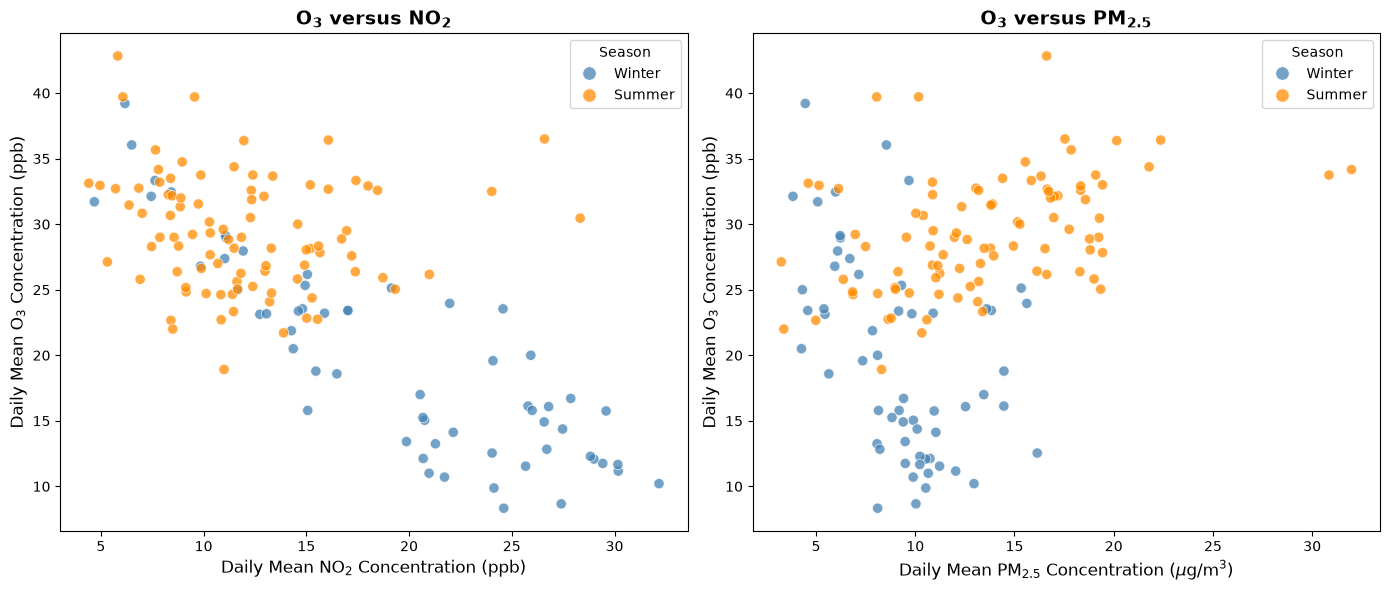

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.scatterplot(data=season_data, x="NO2_ppb", y="O3_ppb", hue="season", hue_order=["Winter", "Summer"], palette={"Winter": "steelblue", "Summer": "darkorange"}, s=55, alpha=0.75, ax=axes[0])
axes[0].set_xlabel(r"Daily Mean NO$_2$ Concentration (ppb)", fontsize=12)
axes[0].set_ylabel(r"Daily Mean O$_3$ Concentration (ppb)", fontsize=12)
axes[0].set_title(r"$\mathbf{O_3}$ versus $\mathbf{NO_2}$", fontsize=14, fontweight="bold")
axes[0].legend(title="Season", markerscale=1.3)

sns.scatterplot(data=season_data, x="PM25_ugm3", y="O3_ppb", hue="season", hue_order=["Winter", "Summer"], palette={"Winter": "steelblue", "Summer": "darkorange"}, s=55, alpha=0.75, ax=axes[1])
axes[1].set_xlabel(r"Daily Mean PM$_{2.5}$ Concentration ($\mu$g/m$^3$)", fontsize=12)
axes[1].set_ylabel(r"Daily Mean O$_3$ Concentration (ppb)", fontsize=12)
axes[1].set_title(r"$\mathbf{O_3}$ versus $\mathbf{PM_{2.5}}$", fontsize=14, fontweight="bold")
axes[1].legend(title="Season", markerscale=1.3)

plt.tight_layout()
plt.show()

The plots show some separation between the classes. Summer generally has
higher O3, while winter tends to have higher NO2. PM2.5 also provides some
separation, although the two classes overlap. Therefore, classification
errors should be expected.



## Ridge Classifier: Training, validation, and test sets

The split is stratified so each subset retains approximately the same class
proportions. The training data fit the models, the validation data select
model settings, and the untouched test data provide the final assessment.



In [9]:
def stratified_split(
    data,
    label_column,
    train_fraction=0.60,
    validation_fraction=0.20,
    seed=31,
):
    random_generator = np.random.RandomState(seed)
    train_indices = []
    validation_indices = []
    test_indices = []

    for label in sorted(data[label_column].unique()):
        class_indices = data.index[data[label_column] == label].to_numpy().copy()
        random_generator.shuffle(class_indices)

        number_class = len(class_indices)
        number_train = int(np.floor(train_fraction * number_class))
        number_validation = int(np.floor(validation_fraction * number_class))

        train_indices.extend(class_indices[:number_train])
        validation_indices.extend(
            class_indices[number_train:number_train + number_validation]
        )
        test_indices.extend(class_indices[number_train + number_validation:])

    random_generator.shuffle(train_indices)
    random_generator.shuffle(validation_indices)
    random_generator.shuffle(test_indices)

    train = data.loc[train_indices].copy()
    validation = data.loc[validation_indices].copy()
    test = data.loc[test_indices].copy()

    return train, validation, test


train_data, validation_data, test_data = stratified_split(
    season_data,
    label_column="season_code",
    seed=31,
)

print("Training observations:", len(train_data))
print("Validation observations:", len(validation_data))
print("Testing observations:", len(test_data))

print("\nTraining classes:")
print(train_data["season"].value_counts())
print("\nValidation classes:")
print(validation_data["season"].value_counts())
print("\nTesting classes:")
print(test_data["season"].value_counts())

Training observations: 90
Validation observations: 29
Testing observations: 32

Training classes:
season
Summer    55
Winter    35
Name: count, dtype: int64

Validation classes:
season
Summer    18
Winter    11
Name: count, dtype: int64

Testing classes:
season
Summer    19
Winter    13
Name: count, dtype: int64


The seed-31 split contains 90 training observations, 29 validation
observations, and 32 test observations.



## Standardize the predictors

Ridge regularization is scale-sensitive. Each predictor is standardized using
only the training mean and standard deviation to prevent data leakage:

$$z=\frac{x-\bar{x}_{\mathrm{train}}}{s_{\mathrm{train}}}$$



In [10]:
features = ["O3_ppb", "NO2_ppb", "PM25_ugm3"]

X_train = train_data[features]
X_validation = validation_data[features]
X_test = test_data[features]

y_train = train_data["season_code"]
y_validation = validation_data["season_code"]
y_test = test_data["season_code"]

training_mean = X_train.mean()
training_std = X_train.std(ddof=0)

X_train_scaled = (X_train - training_mean) / training_std
X_validation_scaled = (X_validation - training_mean) / training_std
X_test_scaled = (X_test - training_mean) / training_std



## Question 2: What cost function is used?

The ridge classifier minimizes squared error with an L2 penalty:

$$J(\mathbf{w},b)=\sum_{i=1}^{n}\left[y_i-(b+\mathbf{x}_i^T\mathbf{w})\right]^2+\alpha\sum_{j=1}^{p}w_j^2$$

A larger alpha produces stronger regularization. Mean squared decision loss is
used to select alpha. Final classification performance is reported using the
misclassification error:

$$\mathrm{Error}=\frac{\text{incorrect predictions}}{\text{total predictions}}$$



In [11]:
alpha_values = np.logspace(-4, 4, 81)

ridge_train_costs = []
ridge_validation_costs = []
ridge_train_errors = []
ridge_validation_errors = []

# RidgeClassifier internally uses class values -1 and +1.
y_train_signed = np.where(y_train == 1, 1, -1)
y_validation_signed = np.where(y_validation == 1, 1, -1)

for alpha in alpha_values:
    model = lm.RidgeClassifier(alpha=alpha)
    model.fit(X_train_scaled, y_train)

    train_scores = model.decision_function(X_train_scaled)
    validation_scores = model.decision_function(X_validation_scaled)

    train_predictions = model.predict(X_train_scaled)
    validation_predictions = model.predict(X_validation_scaled)

    train_cost = np.mean((y_train_signed - train_scores) ** 2)
    validation_cost = np.mean((y_validation_signed - validation_scores) ** 2)

    train_error = np.mean(train_predictions != y_train)
    validation_error = np.mean(validation_predictions != y_validation)

    ridge_train_costs.append(train_cost)
    ridge_validation_costs.append(validation_cost)
    ridge_train_errors.append(train_error)
    ridge_validation_errors.append(validation_error)

ridge_train_costs = np.array(ridge_train_costs)
ridge_validation_costs = np.array(ridge_validation_costs)
ridge_train_errors = np.array(ridge_train_errors)
ridge_validation_errors = np.array(ridge_validation_errors)

best_training_position = np.argmin(ridge_train_costs)
best_validation_position = np.argmin(ridge_validation_costs)

best_training_alpha = alpha_values[best_training_position]
best_validation_alpha = alpha_values[best_validation_position]

print(f"Best training alpha: {best_training_alpha:.4f}")
print(f"Minimum training cost: {ridge_train_costs[best_training_position]:.4f}")
print(f"\nBest validation alpha: {best_validation_alpha:.4f}")
print(f"Minimum validation cost: {ridge_validation_costs[best_validation_position]:.4f}")
print(f"Validation classification error: {ridge_validation_errors[best_validation_position]:.3f}")

Best training alpha: 0.0001
Minimum training cost: 0.5374

Best validation alpha: 6.3096
Minimum validation cost: 0.3340
Validation classification error: 0.069


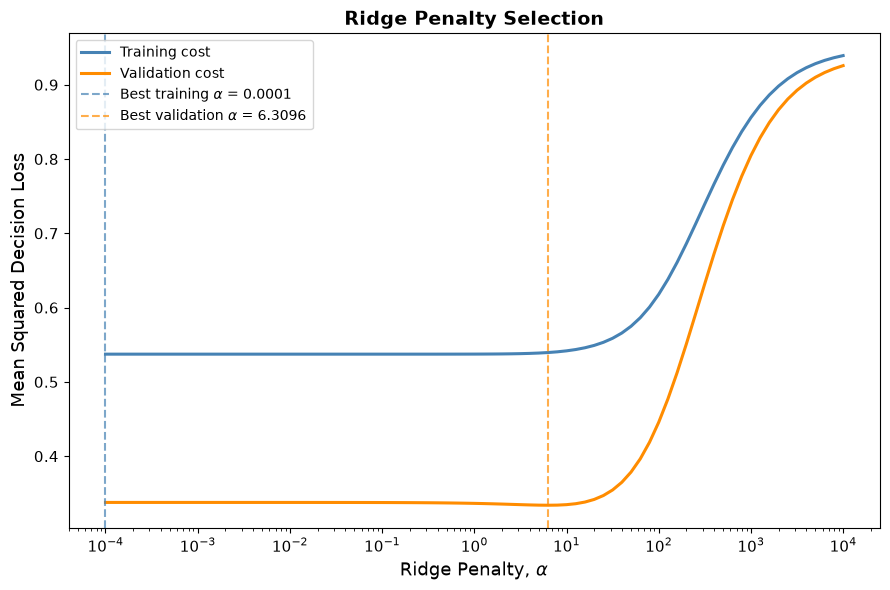

In [12]:
plt.figure(figsize=(9, 6))

plt.plot(alpha_values, ridge_train_costs, color="steelblue", linewidth=2.2, label="Training cost")
plt.plot(alpha_values, ridge_validation_costs, color="darkorange", linewidth=2.2, label="Validation cost")
plt.axvline(best_training_alpha, color="steelblue", linestyle="--", alpha=0.7, label=fr"Best training $\alpha$ = {best_training_alpha:.4f}")
plt.axvline(best_validation_alpha, color="darkorange", linestyle="--", alpha=0.7, label=fr"Best validation $\alpha$ = {best_validation_alpha:.4f}")

plt.xscale("log")
plt.xlabel(r"Ridge Penalty, $\alpha$", fontsize=13)
plt.ylabel("Mean Squared Decision Loss", fontsize=13)
plt.title("Ridge Penalty Selection", fontsize=14, fontweight="bold")
plt.xticks(fontsize=11)
plt.yticks(fontsize=11)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()

## Questions 3 and 4: Optimal ridge penalties

Based only on the training cost, the optimal tested penalty is
$\alpha_{\mathrm{train}}=0.0001$. This is almost no regularization, which is
expected because a more flexible model generally fits its training data more
closely.

The validation cost is minimized at
$\alpha_{\mathrm{validation}}\approx6.31$. This value is selected for the
final ridge classifier because the validation observations were not used to
estimate the model coefficients. The exact optimum depends on the tested
penalty grid.



## Final ridge classifier and honest test error

After selecting alpha, the training and validation observations are combined.
The predictors are standardized again using this combined development set.
The test data remain untouched until the final evaluation.



In [13]:
development_data = pd.concat(
    [train_data, validation_data],
    ignore_index=True,
)

X_development = development_data[features]
y_development = development_data["season_code"]

development_mean = X_development.mean()
development_std = X_development.std(ddof=0)

X_development_scaled = (
    X_development - development_mean
) / development_std

X_test_final_scaled = (
    X_test - development_mean
) / development_std

ridge_final = lm.RidgeClassifier(alpha=best_validation_alpha)
ridge_final.fit(X_development_scaled, y_development)

ridge_test_predictions = ridge_final.predict(X_test_final_scaled)
ridge_test_error = np.mean(
    ridge_test_predictions != y_test.to_numpy()
)
ridge_test_accuracy = 1 - ridge_test_error

print(f"Final ridge test error: {ridge_test_error:.4f}")
print(f"Final ridge test accuracy: {ridge_test_accuracy:.4f}")
print(f"Incorrect predictions: {np.sum(ridge_test_predictions != y_test.to_numpy())}")
print(f"Total test observations: {len(y_test)}")

Final ridge test error: 0.1562
Final ridge test accuracy: 0.8438
Incorrect predictions: 5
Total test observations: 32


In [14]:
ridge_confusion = pd.crosstab(
    pd.Series(y_test.to_numpy(), name="Actual"),
    pd.Series(ridge_test_predictions, name="Predicted"),
)

ridge_confusion = ridge_confusion.rename(
    index={0: "Winter", 1: "Summer"},
    columns={0: "Winter", 1: "Summer"},
)

ridge_confusion

Predicted,Winter,Summer
Actual,,
Winter,9,4
Summer,1,18


## Question 5: Final model error

The final ridge classifier incorrectly classified 5 of the 32 test observations:

$$
\mathrm{Test\ error}
=
\frac{5}{32}
=
0.15625
$$

Therefore, the final test error is approximately **15.6%**, and the corresponding test accuracy is approximately **84.4%**.

This is the most honest assessment of model performance because the test data were not used for training, predictor standardization, or ridge-penalty selection.


## Repeat the split using different seeds



In [15]:
def ridge_split_result(seed):
    train, validation, test = stratified_split(
        season_data,
        label_column="season_code",
        seed=seed,
    )

    X_train_local = train[features]
    X_validation_local = validation[features]
    y_train_local = train["season_code"]
    y_validation_local = validation["season_code"]

    local_mean = X_train_local.mean()
    local_std = X_train_local.std(ddof=0)

    X_train_local_scaled = (
        X_train_local - local_mean
    ) / local_std

    X_validation_local_scaled = (
        X_validation_local - local_mean
    ) / local_std

    y_validation_local_signed = np.where(
        y_validation_local == 1,
        1,
        -1,
    )

    validation_costs = []

    for alpha in alpha_values:
        local_model = lm.RidgeClassifier(alpha=alpha)
        local_model.fit(X_train_local_scaled, y_train_local)

        validation_scores = local_model.decision_function(
            X_validation_local_scaled
        )

        validation_cost = np.mean(
            (y_validation_local_signed - validation_scores) ** 2
        )

        validation_costs.append(validation_cost)

    validation_costs = np.array(validation_costs)
    best_alpha = alpha_values[np.argmin(validation_costs)]

    development = pd.concat(
        [train, validation],
        ignore_index=True,
    )

    X_development_local = development[features]
    y_development_local = development["season_code"]

    development_mean_local = X_development_local.mean()
    development_std_local = X_development_local.std(ddof=0)

    X_development_local_scaled = (
        X_development_local - development_mean_local
    ) / development_std_local

    X_test_local_scaled = (
        test[features] - development_mean_local
    ) / development_std_local

    final_model = lm.RidgeClassifier(alpha=best_alpha)
    final_model.fit(
        X_development_local_scaled,
        y_development_local,
    )

    test_predictions = final_model.predict(
        X_test_local_scaled
    )

    test_error = np.mean(
        test_predictions != test["season_code"].to_numpy()
    )

    return best_alpha, test_error


repeat_results = []

for seed in [1, 7, 21, 31, 42, 99]:
    selected_alpha, test_error = ridge_split_result(seed)

    repeat_results.append({
        "Seed": seed,
        "Selected alpha": selected_alpha,
        "Test error": test_error,
        "Test accuracy": 1 - test_error,
    })

repeat_results = pd.DataFrame(repeat_results)
repeat_results



,Seed,Selected alpha,Test error,Test accuracy
0,1,0.000100,0.15625,0.84375
1,7,7.943282,0.18750,0.81250
2,21,25.118864,0.28125,0.71875
3,31,6.309573,0.15625,0.84375
4,42,5.011872,0.21875,0.78125
5,99,5.011872,0.12500,0.87500


## Question 6: Do repeated splits give the same answers?

No. Changing the random split changes both the selected ridge penalty and the
final test error. For the tested seeds, alpha ranges from approximately
0.0001 to 25.12 and test error ranges from 12.5% to 28.1%. The dataset has
only 151 observations, so moving a few difficult observations between subsets
can noticeably affect the results. Repeated cross-validation would provide a
more stable estimate.



## Compare with logistic regression

Logistic regression uses binary cross-entropy, or log loss:

$$-\frac{1}{n}\sum_{i=1}^{n}\left[y_i\log(p_i)+(1-y_i)\log(1-p_i)\right]$$

In scikit-learn, C is the inverse of regularization strength. Smaller C means
stronger regularization. C is selected using validation log loss.



In [16]:
C_values = np.logspace(-4, 4, 81)
logistic_validation_losses = []
logistic_validation_errors = []

for C in C_values:
    logistic_model = lm.LogisticRegression(
        C=C,
        max_iter=10000,
    )

    logistic_model.fit(X_train_scaled, y_train)

    validation_probabilities = logistic_model.predict_proba(
        X_validation_scaled
    )[:, 1]

    validation_probabilities = np.clip(
        validation_probabilities,
        1e-15,
        1 - 1e-15,
    )

    validation_predictions = logistic_model.predict(
        X_validation_scaled
    )

    validation_log_loss = -np.mean(
        y_validation.to_numpy() * np.log(validation_probabilities)
        + (1 - y_validation.to_numpy())
        * np.log(1 - validation_probabilities)
    )

    validation_error = np.mean(
        validation_predictions != y_validation.to_numpy()
    )

    logistic_validation_losses.append(validation_log_loss)
    logistic_validation_errors.append(validation_error)

logistic_validation_losses = np.array(logistic_validation_losses)
logistic_validation_errors = np.array(logistic_validation_errors)

best_C_position = np.argmin(logistic_validation_losses)
best_C = C_values[best_C_position]

print(f"Best logistic C: {best_C:.4f}")
print(f"Minimum validation log loss: {logistic_validation_losses[best_C_position]:.4f}")
print(f"Validation classification error: {logistic_validation_errors[best_C_position]:.3f}")



Best logistic C: 10000.0000
Minimum validation log loss: 0.1850
Validation classification error: 0.069


In [17]:
logistic_final = lm.LogisticRegression(
    C=best_C,
    max_iter=10000,
)

logistic_final.fit(
    X_development_scaled,
    y_development,
)

logistic_test_predictions = logistic_final.predict(
    X_test_final_scaled
)

logistic_test_error = np.mean(
    logistic_test_predictions != y_test.to_numpy()
)

logistic_test_accuracy = 1 - logistic_test_error

print(f"Logistic test error: {logistic_test_error:.4f}")
print(f"Logistic test accuracy: {logistic_test_accuracy:.4f}")



Logistic test error: 0.1250
Logistic test accuracy: 0.8750


In [18]:
model_comparison = pd.DataFrame({
    "Model": ["Ridge classifier", "Logistic regression"],
    "Selected parameter": [best_validation_alpha, best_C],
    "Test error": [ridge_test_error, logistic_test_error],
    "Test accuracy": [ridge_test_accuracy, logistic_test_accuracy],
})

model_comparison



,Model,Selected parameter,Test error,Test accuracy
0,Ridge classifier,6.309573,0.15625,0.84375
1,Logistic regression,10000.000000,0.12500,0.87500


# Question 7: Which model performs best?

With the seed-31 split, the ridge classifier incorrectly classified 5 of the 32 test observations:

$$
\mathrm{Ridge\ error}
=
\frac{5}{32}
=
0.15625
=
15.6\%
$$

The logistic regression model incorrectly classified 4 of the 32 test observations:

$$
\mathrm{Logistic\ error}
=
\frac{4}{32}
=
0.125
=
12.5\%
$$

The ridge classifier achieved a test accuracy of approximately **84.4%**, while logistic regression achieved approximately **87.5%**.

Therefore, logistic regression performed slightly better for the seed-31 split. It made one fewer incorrect prediction and had a 3.1-percentage-point higher test accuracy. However, this conclusion applies specifically to this data split, and the comparison may change when a different random seed is used.